# Pipeline mimiSBM générique avec critères de sélection de modèle (ILvb, ICL variationnel, ICL approché) pour la famille de descripteurs Ka Ks

## Imports

In [1]:
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pickle

from scipy.special import entr
from sklearn.metrics import adjusted_rand_score

from mimisbm_main.mimisbm._base import MimiSBM

## 1. Configuration — chemins des matrices d'adjacence et hyperparametres

In [2]:
# nom de vue -> chemin matrice d'adjacence correspondante
ADJACENCY_PATHS = {
    path.name.split("silh_", 1)[1].removesuffix(".csv"): path
    for path in [
        Path(r"/mnt/c/Users/thoma/OneDrive/Documents/ENSIIE/Master/Stage 3A/Données/adjacency/lda/family/adjacency_matrix_silh_Ka.csv"),
        Path(r"/mnt/c/Users/thoma/OneDrive/Documents/ENSIIE/Master/Stage 3A/Données/adjacency/lda/family/adjacency_matrix_silh_Ks.csv"),
    ]
}
OUTPUT_DIR = Path(r"/mnt/c/Users/thoma/OneDrive/Documents/ENSIIE/Master/Stage 3A/mimiSBM/Plots/mimiSBM/KaKs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Hyperparametres de la recherche de modele
K_VALUES = range(2, 11)   # nombre de clusters d'individus a tester
Q_VALUES = range(1, 5)    # nombre de composantes de vues a tester
N_INIT = 10                # nombre d'initialisations par couple (K, Q), equivalent au n_init R
PRIORS = "jeffreys"        # ou "uniform", ou un tableau numpy
MAX_ITER = 100
TOL = 1e-6
BASE_SEED = 0
SELECTION_CRITERION = "ILVB"  # "ILVB", "ICL_variationnel" ou "ICL_approx" : critere utilise
                                # par defaut pour choisir le modele final (section 8)

## 2. Chargement generique et validation des matrices d'adjacence

In [3]:
def load_adjacency_matrices(paths: dict) -> dict:
    """Charge et valide un ensemble de matrices d'adjacence binaires.

    Args:
        paths: dict {nom_de_vue: chemin_matrice_d'adjacence}.

    Returns:
        dict {nom_de_vue: matrice numpy (N x N) binaire}.

    Raises:
        ValueError: si une matrice contient des valeurs hors {0, 1}, ou si les tailles
            des matrices ne sont pas toutes identiques.
    """
    adj_dict = {}
    shapes = set()
    for name, path in paths.items():
        path = Path(path)
        adj = pd.read_csv(path, index_col=0).values

        uniq = np.unique(adj)
        print(f"[{name}] shape={adj.shape}, valeurs uniques={sorted(uniq.tolist())}")
        if not np.all(np.isin(uniq, [0, 1])):
            raise ValueError(f"{name} : valeurs differentes de 0 et 1 detectees.")

        adj_dict[name] = adj.astype(np.int64)
        shapes.add(adj.shape[0])

    if len(shapes) > 1:
        raise ValueError(f"Tailles de matrices incoherentes entre vues : {shapes}")

    return adj_dict

## 3. Assemblage et verification du tenseur A (N x N x V)

In [4]:
def build_tensor(adj_dict: dict):
    """Assemble les matrices d'adjacence des vues en tenseur (N, N, V).

    Returns:
        (A, names) ou A est le tenseur numpy et names l'ordre des vues dans le tenseur.
    """
    names = list(adj_dict.keys())
    N = adj_dict[names[0]].shape[0]
    V = len(names)

    assert all(adj_dict[n].shape == (N, N) for n in names), "Toutes les vues doivent etre NxN de meme taille."

    A = np.zeros((N, N, V), dtype=np.int64)
    for i, name in enumerate(names):
        adj = adj_dict[name].copy()
        np.fill_diagonal(adj, 0)
        if not np.array_equal(adj, adj.T):
            adj = np.maximum(adj, adj.T)
        A[:, :, i] = adj

    assert A.shape == (N, N, V)
    assert all(np.array_equal(A[:, :, v], A[:, :, v].T) for v in range(V))
    assert all(np.all(np.diag(A[:, :, v]) == 0) for v in range(V))

    return A, names

## 4. Chargement effectif a partir de la configuration

In [5]:
adj_dict = load_adjacency_matrices(ADJACENCY_PATHS)
A, view_names = build_tensor(adj_dict)

N, _, V = A.shape
print(f"\nTenseur A : shape={A.shape}  (N={N} individus, V={V} vues)")

tensor_path = OUTPUT_DIR / "adjacency_tensor.npy"
np.save(tensor_path, A)
print(f"Tenseur sauvegarde : {tensor_path}")

[Ka] shape=(444, 444), valeurs uniques=[0, 1]
[Ks] shape=(444, 444), valeurs uniques=[0, 1]

Tenseur A : shape=(444, 444, 2)  (N=444 individus, V=2 vues)
Tenseur sauvegarde : /mnt/c/Users/thoma/OneDrive/Documents/ENSIIE/Master/Stage 3A/mimiSBM/Plots/mimiSBM/KaKs/adjacency_tensor.npy


## 5. Ajustement mimiSBM multi-init (equivalent `n_init` R)

In [6]:
def fit_best_of_n_init(A, K, Q, n_init=N_INIT, priors=PRIORS, max_iter=MAX_ITER,
                        tol=TOL, base_seed=BASE_SEED, verbose=False):
    """Ajuste MimiSBM plusieurs fois pour (K, Q) et retient le meilleur ELBO.
    
    Returns:
        (best_model, best_seed)
    """
    best_model, best_elbo, best_seed = None, -np.inf, None
    for i in range(n_init):
        seed = base_seed + i
        model = MimiSBM(
            n_clusters=K, n_components=Q,
            clusters_prior=priors, components_prior=priors, adjacency_prior=priors,
            max_iter=max_iter, tol=tol, random_state=seed,
        )
        model.fit(A)
        if verbose:
            print(f"  run {i} (seed={seed}) : ELBO={model.elbo_:.2f}  converged={model.converged_}")
        if model.elbo_ > best_elbo:
            best_elbo, best_model, best_seed = model.elbo_, model, seed
    return best_model, best_seed

## 6. Criteres de selection de modele : ILvb, ICL variationnel, ICL approche

- **ILvb** : `model.elbo_` directement (evidence + entropie des responsabilites).
- **ICL variationnel** : `ILvb - entropie(tau) - entropie(u)`, c'est-a-dire seulement la
  partie evidence de l'ELBO, calculee avec les parametres variationnels *soft* (tau, u).
- **ICL approche** : `ILvb - pen(K, Q)`, avec la penalite BIC-type

  `pen(K,Q) = 1/2 * K(K+1)/2*Q * log(V*N(N-1)/2) + 1/2*(K-1)*log(N) + 1/2*(Q-1)*log(V)`

  qui penalise la complexite (K, Q) en plus de l'ajustement aux donnees.

In [7]:
def variational_icl(model):
    """ICL variationnel = ELBO (ILvb) moins l'entropie des responsabilites (tau, u)."""
    cluster_entropy = entr(model.cluster_responsibilities_).sum()
    component_entropy = entr(model.component_responsibilities_).sum()
    print(cluster_entropy, component_entropy)
    return model.elbo_ - (cluster_entropy + component_entropy)


def approximate_icl(model, N, V):
    """ICL approche (BIC-type) : ELBO (ILvb) moins une penalite de complexite pen(K, Q)."""
    K, Q = model.n_clusters, model.n_components
    pen = (
        0.5 * (K * (K + 1) / 2 * Q) * np.log(V * N * (N - 1) / 2)
        + 0.5 * (K - 1) * np.log(N)
        + 0.5 * (Q - 1) * np.log(V)
    )
    return model.elbo_ - pen

## 7. Recherche de grille (K, Q) avec les trois criteres

Une seule boucle K x Q x n_init : chaque modele ajuste est evalue selon les trois criteres
a la fois (pas de refit supplementaire), et le meilleur (K, Q) est retenu separement pour
chacun.

In [8]:
def grid_search_all_criteria(A, K_values, Q_values, n_init=N_INIT, **kwargs):
    """Recherche de grille (K, Q) evaluee selon ILVB, ICL_variationnel et ICL_approx.

    Returns:
        (results_df, bests) ou bests = {"ILVB": {...}, "ICL_variationnel": {...}, "ICL_approx": {...}}
        et chaque entree contient {"crit", "model", "K", "Q"}.
    """
    N, _, V = A.shape
    results = []
    bests = {
        "ILVB": {"crit": -np.inf, "model": None, "K": None, "Q": None},
        "ICL_variationnel": {"crit": -np.inf, "model": None, "K": None, "Q": None},
        "ICL_approx": {"crit": -np.inf, "model": None, "K": None, "Q": None},
    }
    for K in K_values:
        for Q in Q_values:
            model, seed = fit_best_of_n_init(A, K, Q, n_init=n_init, **kwargs)
            ilvb = model.elbo_
            icl_var = variational_icl(model)
            icl_app = approximate_icl(model, N, V)

            results.append({
                "K": K, "Q": Q, "ILVB": ilvb, "ICL_variationnel": icl_var,
                "ICL_approx": icl_app, "converged": model.converged_, "best_seed": seed,
            })
            print(f"K={K}, Q={Q} : ILVB={ilvb:.2f}  ICL_var={icl_var:.2f}  ICL_approx={icl_app:.2f}")

            for name, val in [("ILVB", ilvb), ("ICL_variationnel", icl_var), ("ICL_approx", icl_app)]:
                if val > bests[name]["crit"]:
                    bests[name].update(crit=val, model=model, K=K, Q=Q)

    return pd.DataFrame(results), bests


results_df, bests = grid_search_all_criteria(A, K_VALUES, Q_VALUES, n_init=N_INIT)

print()
for name, b in bests.items():
    print(f"{name:18s} : meilleur (K, Q) = ({b['K']}, {b['Q']})  |  valeur = {b['crit']:.2f}")

2.9583182716627998e-297 0.0
K=2, Q=1 : ILVB=-95761.53  ICL_var=-95761.53  ICL_approx=-95782.86
0.0 0.0
K=2, Q=2 : ILVB=-64113.08  ICL_var=-64113.08  ICL_approx=-64153.04
0.0 0.0
K=2, Q=3 : ILVB=-64113.71  ICL_var=-64113.71  ICL_approx=-64172.30
0.0 0.0
K=2, Q=4 : ILVB=-64114.18  ICL_var=-64114.18  ICL_approx=-64191.40
6.298049952890496e-85 0.0
K=3, Q=1 : ILVB=-71839.86  ICL_var=-71839.86  ICL_approx=-71882.52
0.0 0.0
K=3, Q=2 : ILVB=-26298.24  ICL_var=-26298.24  ICL_approx=-26377.81
0.0 0.0
K=3, Q=3 : ILVB=-26298.86  ICL_var=-26298.86  ICL_approx=-26415.36
0.0 0.0
K=3, Q=4 : ILVB=-26299.33  ICL_var=-26299.33  ICL_approx=-26452.74
0.0 0.0
K=4, Q=1 : ILVB=-62627.53  ICL_var=-62627.53  ICL_approx=-62697.62
0.0 0.0
K=4, Q=2 : ILVB=-11369.58  ICL_var=-11369.58  ICL_approx=-11500.97
0.0 0.0
K=4, Q=3 : ILVB=-11370.21  ICL_var=-11370.21  ICL_approx=-11562.89
0.0 0.0
K=4, Q=4 : ILVB=-11370.68  ICL_var=-11370.68  ICL_approx=-11624.65
3.3828132626176682e-152 0.0
K=5, Q=1 : ILVB=-56382.68  ICL_var

## 8. Visualisation : ELBO et comparaison des trois criteres

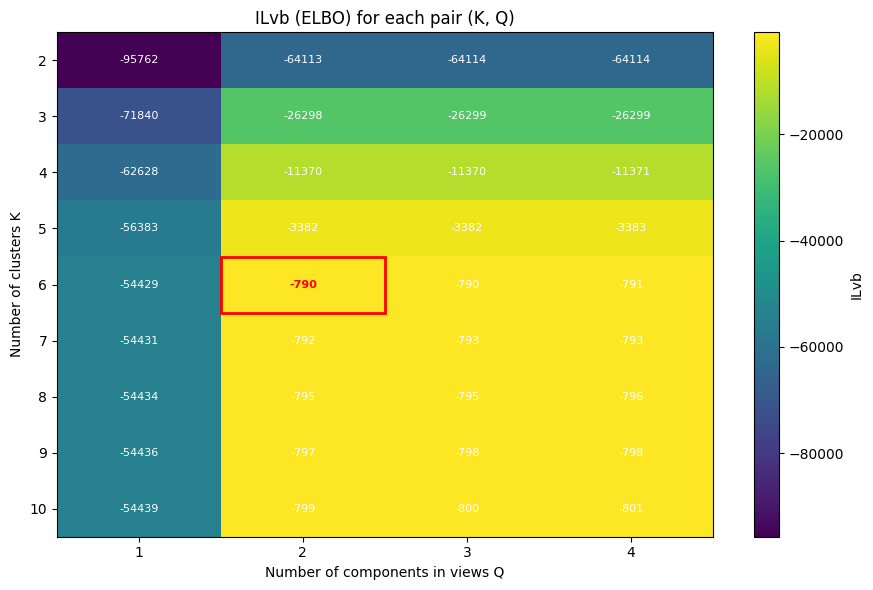

,K,Q,valeur
ILVB,6.0,2.0,-789.718971
ICL_variationnel,6.0,2.0,-789.718971
ICL_approx,6.0,2.0,-1061.282387


In [17]:
elbo_matrix = results_df.pivot(index="K", columns="Q", values="ILVB")
max_elbo = elbo_matrix.max().max()

plt.figure(figsize=(9, 6))
plt.imshow(elbo_matrix.values, aspect="auto", cmap="viridis")
plt.xticks(range(len(elbo_matrix.columns)), elbo_matrix.columns)
plt.yticks(range(len(elbo_matrix.index)), elbo_matrix.index)
plt.xlabel("Number of components in views Q")
plt.ylabel("Number of clusters K")
plt.title("ILvb (ELBO) for each pair (K, Q)")

for i in range(elbo_matrix.shape[0]):
    for j in range(elbo_matrix.shape[1]):
        value = elbo_matrix.iloc[i, j]
        is_max = value == max_elbo

        plt.text(
            j, i, f"{value:.0f}",
            ha="center", va="center",
            color="red" if is_max else "white",
            fontsize=8,
            fontweight="bold" if is_max else "normal",
        )

        if is_max:
            plt.gca().add_patch(
                plt.Rectangle(
                    (j - 0.5, i - 0.5), 1, 1,
                    fill=False, edgecolor="red", linewidth=2
                )
            )

plt.colorbar(label="ILvb")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "ilvb_heatmap.png", dpi=300)
plt.show()

# Comparaison des (K, Q) retenus par chaque critere
comparison = pd.DataFrame({
    name: {"K": b["K"], "Q": b["Q"], "valeur": b["crit"]}
    for name, b in bests.items()
}).T
comparison

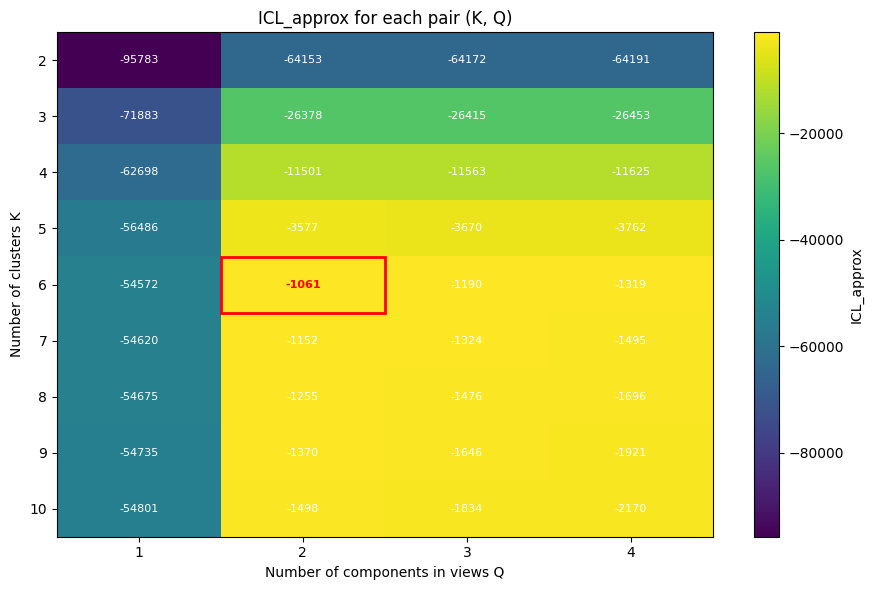

In [16]:
elbo_matrix = results_df.pivot(index="K", columns="Q", values="ICL_approx")
max_elbo = elbo_matrix.max().max()

plt.figure(figsize=(9, 6))
plt.imshow(elbo_matrix.values, aspect="auto", cmap="viridis")
plt.xticks(range(len(elbo_matrix.columns)), elbo_matrix.columns)
plt.yticks(range(len(elbo_matrix.index)), elbo_matrix.index)
plt.xlabel("Number of components in views Q")
plt.ylabel("Number of clusters K")
plt.title("ICL_approx for each pair (K, Q)")

for i in range(elbo_matrix.shape[0]):
    for j in range(elbo_matrix.shape[1]):
        value = elbo_matrix.iloc[i, j]
        is_max = value == max_elbo

        plt.text(
            j, i, f"{value:.0f}",
            ha="center", va="center",
            color="red" if is_max else "white",
            fontsize=8,
            fontweight="bold" if is_max else "normal",
        )

        if is_max:
            plt.gca().add_patch(
                plt.Rectangle(
                    (j - 0.5, i - 0.5), 1, 1,
                    fill=False, edgecolor="red", linewidth=2
                )
            )

plt.colorbar(label="ICL_approx")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "icl_approx_heatmap.png", dpi=300)
plt.show()

## 9. Resultats du modele retenu

Par defaut, le modele retenu est celui du critere `SELECTION_CRITERION` defini en
configuration (section 1). L'ICL approximate étant plus penalisant que l'ILvb, il peut
retenir un (K, Q) plus petit — regarder la comparaison des 3 critères pour voir si les
criteres divergent sur les donnees.

In [11]:
best_model = bests[SELECTION_CRITERION]["model"]
node_clusters, view_components = best_model.predict()

print(f"Critere utilise : {SELECTION_CRITERION}  |  (K, Q) = ({bests[SELECTION_CRITERION]['K']}, {bests[SELECTION_CRITERION]['Q']})")

print("\nTailles des clusters d'individus (K):")
print(pd.Series(node_clusters).value_counts().sort_index())

print("\nComposante de vue retenue par vue:")
print(pd.DataFrame({"vue": view_names, "composante": view_components}))

model_path = OUTPUT_DIR / "mimiSBM_best_model.pkl"
with open(model_path, "wb") as f:
    pickle.dump(best_model, f)
print(f"\nModele sauvegarde : {model_path}")

Critere utilise : ILVB  |  (K, Q) = (6, 2)

Tailles des clusters d'individus (K):
0    191
1    108
2    102
3     26
4     13
5      4
Name: count, dtype: int64

Composante de vue retenue par vue:
  vue  composante
0  Ka           0
1  Ks           1

Modele sauvegarde : /mnt/c/Users/thoma/OneDrive/Documents/ENSIIE/Master/Stage 3A/mimiSBM/Plots/mimiSBM/KaKs/mimiSBM_best_model.pkl


## 10. Test de stabilite du clustering entre initialisations (ARI)

Pour le (K, Q) retenu par `SELECTION_CRITERION`, on relance plusieurs fits independants et
on mesure l'ARI entre les partitions obtenues.

In [12]:
def stability_test(A, K, Q, n_init=N_INIT, **kwargs):
    """Mesure la stabilite (ARI) du clustering entre plusieurs runs pour un (K, Q) fixe.
    Returns:
        (ari_z, ari_w) : liste des ARI entre les partitions d'individus et de vues.
    """
    zs, ws = [], []
    for i in range(n_init):
        model, _ = fit_best_of_n_init(A, K, Q, n_init=1, base_seed=1000 + i, **kwargs)
        z, w = model.predict()
        zs.append(z); ws.append(w)
    ari_z = [adjusted_rand_score(a, b) for a, b in combinations(zs, 2)]
    ari_w = [adjusted_rand_score(a, b) for a, b in combinations(ws, 2)]
    return ari_z, ari_w


K_sel, Q_sel = bests[SELECTION_CRITERION]["K"], bests[SELECTION_CRITERION]["Q"]
ari_z, ari_w = stability_test(A, K_sel, Q_sel, n_init=N_INIT)

print(f"ARI clusters individus (K={K_sel})  - moyenne={np.mean(ari_z):.3f}, min={np.min(ari_z):.3f}")
print(f"ARI composantes de vues (Q={Q_sel}) - moyenne={np.mean(ari_w):.3f}, min={np.min(ari_w):.3f}")

ARI clusters individus (K=6)  - moyenne=0.999, min=0.997
ARI composantes de vues (Q=2) - moyenne=1.000, min=1.000


In [13]:
def stability_test(A, K, Q, n_init=N_INIT, **kwargs):
    """Mesure la stabilite (ARI) du clustering entre plusieurs runs pour un (K, Q) fixe.
    Returns:
        (ari_z, ari_w) : liste des ARI entre les partitions d'individus et de vues.
    """
    zs, ws = [], []
    for i in range(n_init):
        model, _ = fit_best_of_n_init(A, K, Q, n_init=1, base_seed=1000 + i, **kwargs)
        z, w = model.predict()
        zs.append(z); ws.append(w)
    ari_z = [adjusted_rand_score(a, b) for a, b in combinations(zs, 2)]
    ari_w = [adjusted_rand_score(a, b) for a, b in combinations(ws, 2)]
    return ari_z, ari_w


K_sel, Q_sel = bests["ICL_approx"]["K"], bests["ICL_approx"]["Q"]
ari_z, ari_w = stability_test(A, K_sel, Q_sel, n_init=N_INIT)

print(f"ARI clusters individus (K={K_sel})  - moyenne={np.mean(ari_z):.3f}, min={np.min(ari_z):.3f}")
print(f"ARI composantes de vues (Q={Q_sel}) - moyenne={np.mean(ari_w):.3f}, min={np.min(ari_w):.3f}")

ARI clusters individus (K=6)  - moyenne=0.999, min=0.997
ARI composantes de vues (Q=2) - moyenne=1.000, min=1.000


## 11. Test de validation — pipeline sur donnees simulees (K, Q connus)

On simule un tenseur avec un K et un Q connus, puis on verifie que les trois criteres
retrouvent bien ces valeurs sur un exemple ou le signal est net.

In [14]:
def simulate_mimisbm_tensor(N, V, K, Q, seed=0):
    """Simule un tenseur (N, N, V) suivant le modele generatif mimiSBM, K et Q connus.
    Returns:
        (A_sim, z_true, w_true) : tenseur simule, clusters d'individus et composantes de vues.
    """
    rng = np.random.default_rng(seed)
    z_true = rng.integers(0, K, size=N)
    w_true = np.array([i % Q for i in range(V)])
    rng.shuffle(w_true)

    alpha = np.zeros((K, K, Q))
    alpha[:, :, 0] = 0.05
    np.fill_diagonal(alpha[:, :, 0], 0.9)
    for s in range(1, Q):
        alpha[:, :, s] = 0.55
        np.fill_diagonal(alpha[:, :, s], 0.1)

    A_sim = np.zeros((N, N, V), dtype=np.int64)
    for v in range(V):
        s = w_true[v]
        P = alpha[z_true][:, z_true, s]
        draw = (rng.random((N, N)) < P).astype(np.int64)
        draw = np.triu(draw, 1)
        A_sim[:, :, v] = draw + draw.T

    return A_sim, z_true, w_true


K_TRUE, Q_TRUE = 3, 2
A_sim, z_true, w_true = simulate_mimisbm_tensor(N=60, V=6, K=K_TRUE, Q=Q_TRUE, seed=0)

sim_results_df, sim_bests = grid_search_all_criteria(
    A_sim, K_values=range(2, 5), Q_values=range(1, 4), n_init=3, max_iter=100,
)

print()
for name, b in sim_bests.items():
    z_pred, w_pred = b["model"].predict()
    ari_z = adjusted_rand_score(z_true, z_pred)
    ari_w = adjusted_rand_score(w_true, w_pred)
    ok = "OK" if (b["K"], b["Q"]) == (K_TRUE, Q_TRUE) else "DIFFERENT"
    print(f"{name:18s} : (K,Q)=({b['K']}, {b['Q']})  vrai=({K_TRUE},{Q_TRUE})  [{ok}]  "
          f"ARI individus={ari_z:.3f}  ARI vues={ari_w:.3f}")

0.07812300068847113 0.0
K=2, Q=1 : ILVB=-6902.80  ICL_var=-6902.88  ICL_approx=-6918.76
2.0150715672442797e-88 0.0
K=2, Q=2 : ILVB=-5595.26  ICL_var=-5595.26  ICL_approx=-5626.02
8.38459994674965e-89 0.09256195144887291
K=2, Q=3 : ILVB=-5603.49  ICL_var=-5603.58  ICL_approx=-5649.05
0.028146675785003256 0.0
K=3, Q=1 : ILVB=-6841.75  ICL_var=-6841.78  ICL_approx=-6873.66
9.264135647406056e-127 0.0
K=3, Q=2 : ILVB=-4334.50  ICL_var=-4334.50  ICL_approx=-4395.12
1.7742915147452227e-127 0.0026493254058273345
K=3, Q=3 : ILVB=-4347.27  ICL_var=-4347.27  ICL_approx=-4436.59
0.02814667579324969 0.0
K=4, Q=1 : ILVB=-6843.69  ICL_var=-6843.71  ICL_approx=-6896.18
9.26413564740579e-127 0.0
K=4, Q=2 : ILVB=-4336.44  ICL_var=-4336.44  ICL_approx=-4436.18
1.7742915147661964e-127 0.002649325407204078
K=4, Q=3 : ILVB=-4349.20  ICL_var=-4349.21  ICL_approx=-4496.19

ILVB               : (K,Q)=(3, 2)  vrai=(3,2)  [OK]  ARI individus=1.000  ARI vues=1.000
ICL_variationnel   : (K,Q)=(3, 2)  vrai=(3,2)  [O